# HSA_Cam_B_001.py
## Testing HSA_Cam_B_001_lib.py

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import ICIW_Plots
from ICIW_Plots import make_square_subplots, cm2inch
import numpy as np
import pytensor as pt

pt.config.mode = "JAX"

plt.style.use("ICIWstyle")

In [2]:
from HSA_Cam_B_001_lib import (
    forward_solve,
    vec_forward_solve,
    SIDX,
    PIDX,
    _forward_solve,
    _vec_forward_solve,
    _ODE_func,
    _jitted_forward_solve,
    _jitted_vec_forward_solve,
)

In [3]:
def plot_hydrogenation_results(sol):
    fig = ICIW_Plots.figure(
        layout="double_column",
        height=1.5 * ICIW_Plots.size("ICIW", "double_column", "in"),
    )
    axs = make_square_subplots(
        fig=fig,
        ax_layout=(3, 2),
        ax_width=5.5 * cm2inch,
        h_sep=0.7,
        left_h=1,
        v_sep=0.5,
        sharex=True,
        sharelabel=True,
        xlabel=r"$t$ / $\mathrm{min}$",
        ylabel=[r"$m$ / $\mathrm{kg}$", r"$m$ / $\mathrm{kg}$", r"$a$ / 1"],
    )

    for spec in ["RDY", "RYE", "RYA", "REA", "RDEt"]:
        axs[0, 0].plot(
            sol.t / 60,
            sol.y[SIDX[spec], :].T,
            label=spec,
        )
    axs[0, 0].set_title(r"RDY-RDEt")
    axs[0, 0].legend()
    # axs[0, 1].plot(sol.t / 60, sol.m[4, :])
    # axs[0, 1].plot(sol.t / 60, sol.y[SIDX["RDEt(X)"], :])

    axs[0, 1].plot(sol.t / 60, sol.y[SIDX["dimerA"], :], label="dimerA")
    axs[0, 1].plot(sol.t / 60, sol.y[SIDX["dimerY"], :], label="dimerY")
    axs[0, 1].plot(
        sol.t / 60,
        sol.y[SIDX["dimerA"], :] + sol.y[SIDX["dimerY"], :],
        "k--",
        label="total",
    )
    axs[0, 1].set_title(r"post RDEt products")
    axs[0, 1].legend()

    axs[1, 0].plot(sol.t / 60, sol.y[SIDX["H2"], :], label="(aq)")
    axs[1, 0].plot(sol.t / 60, sol.y[SIDX["conH2[G]"], :], "--", label="cum. (g)")
    axs[1, 0].set_title(r"H_2")
    axs[1, 0].legend()
    axs[1, 1].plot(sol.t / 60, sol.y[SIDX["RDY"], :], label="(aq)")
    axs[1, 1].plot(sol.t / 60, sol.y[SIDX["RDY[S]"], :], "--", label="(s)")
    axs[1, 1].set_title(r"RDY")
    axs[1, 1].legend()

    axs[2, 0].plot(sol.t / 60, sol.y[SIDX["a"], :])
    axs[2, 0].set_title(r"catalyst activity")

    plt.show()

In [4]:
def plot_posterior_results(t_obs, idata, key="prior", fig=None, axs=None):

    prior_predictive = idata[key]["y_hat"].data.reshape(-1, t_obs.shape[0], 18)

    if fig is None or axs is None:
        fig = ICIW_Plots.figure(
            layout="double_column",
            height=1.5 * ICIW_Plots.size("ICIW", "double_column", "in"),
        )
        axs = make_square_subplots(
            fig=fig,
            ax_layout=(3, 2),
            ax_width=5.5 * cm2inch,
            h_sep=0.7,
            left_h=1,
            v_sep=0.5,
            sharex=True,
            sharelabel=True,
            xlabel=r"$t$ / $\mathrm{min}$",
            ylabel=[r"$m$ / $\mathrm{kg}$", r"$m$ / $\mathrm{kg}$", r"$a$ / 1"],
        )

    axs[0, 0].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["RDEt"]].T,
        lw=0.2,
        color="C0",
        ls="--",
    )
    axs[0, 0].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["RDEt"]].mean(axis=0),
        color="C0",
        ls="--",
    )
    axs[0, 0].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["RDY"]].T,
        lw=0.2,
        color="C1",
        ls="--",
    )
    axs[0, 0].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["RDY"]].mean(axis=0),
        color="C1",
        ls="--",
    )
    axs[0, 0].set_title(r"RDY & RDEt")

    axs[0, 1].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["dimerA"]].T,
        lw=0.2,
        color="C0",
        ls="--",
    )
    axs[0, 1].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["dimerY"]].T,
        lw=0.2,
        color="C1",
        ls="--",
    )
    axs[0, 1].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["dimerA"]].T
        + prior_predictive[:, :, SIDX["dimerY"]].T,
        lw=0.2,
        color="k",
        ls="--",
    )
    axs[0, 1].plot(
        t_obs / 60,
        (
            prior_predictive[:, :, SIDX["dimerA"]]
            + prior_predictive[:, :, SIDX["dimerY"]]
        ).mean(axis=0),
        color="k",
        ls="--",
    )
    axs[0, 1].set_title(r"post RDEt products")
    axs[0, 1].legend()

    axs[1, 0].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["conH2[G]"]].T,
        "--",
        lw=0.2,
        color="C0",
    )
    axs[1, 0].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["conH2[G]"]].mean(axis=0),
        "--",
        color="C0",
    )
    axs[1, 0].set_title(r"H_2")
    axs[1, 0].legend()
    axs[1, 1].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["RDY[S]"]].T,
        "--",
        lw=0.2,
        color="C0",
    )
    axs[1, 1].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["RDY[S]"]].mean(axis=0),
        "--",
        color="C0",
    )
    axs[1, 1].set_title(r"RDY")

    axs[2, 0].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["a"]].T,
        lw=0.2,
        color="C0",
        ls="--",
    )
    axs[2, 0].plot(
        t_obs / 60,
        prior_predictive[:, :, SIDX["a"]].mean(axis=0),
        color="C0",
        ls="--",
    )
    axs[2, 0].set_title(r"catalyst activity")

    return fig, axs

In [5]:
m_li0 = jnp.array(
    [
        0.2574,
        0.194,
        0.0,
        0.00235,
        0.00235,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
    ]
)
p = 10 * 1.01325e5  # Pa
T = 293.15  # K
m_s0 = 0.08784  # kg
k_deact = 1e-4
EA_deact = 50000  # J/mol
deact_order = 0.7

t = jnp.linspace(0, 150 * 60, 10)  # s
print(steps := 10 * 150 * 60)
print(np.log(steps))

90000
11.407564949312402


In [6]:
y0 = jnp.concatenate((m_li0, jnp.array([m_s0, 0.0, T, 1.0])))
params = jnp.array([p, m_s0, k_deact, EA_deact, deact_order])

In [7]:
from types import SimpleNamespace

sol = SimpleNamespace()
sol.y = _forward_solve(y0, t, params).T
sol.t = t
print(sol.y)

[[2.57400000e-01 2.57400000e-01 2.57400000e-01 2.57400000e-01
  2.57400000e-01 2.57400000e-01 2.57400000e-01 2.57400000e-01
  2.57400000e-01 2.57400000e-01]
 [1.94000000e-01 1.94000000e-01 1.94000000e-01 1.94000000e-01
  1.94000000e-01 1.94000000e-01 1.94000000e-01 1.94000000e-01
  1.94000000e-01 1.94000000e-01]
 [0.00000000e+00 4.08393404e-06 4.75371066e-06 5.25473381e-06
  5.64864711e-06 5.96753101e-06 6.23085493e-06 6.45138685e-06
  6.63795757e-06 6.79693087e-06]
 [2.35000000e-03 1.40460180e-03 1.34723959e-03 1.30862911e-03
  1.28043329e-03 1.25883836e-03 1.24176283e-03 1.22795299e-03
  1.21660035e-03 1.20715586e-03]
 [2.35000000e-03 1.55625004e-05 7.57536670e-06 5.39676893e-06
  4.38189396e-06 3.79753317e-06 3.42015216e-06 3.15846497e-06
  2.96817115e-06 2.82513566e-06]
 [0.00000000e+00 9.64306160e-04 1.02281562e-03 1.06219831e-03
  1.09095804e-03 1.11298487e-03 1.13040191e-03 1.14448795e-03
  1.15606765e-03 1.16570102e-03]
 [0.00000000e+00 8.15306927e-05 7.04841792e-05 6.36086089e

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


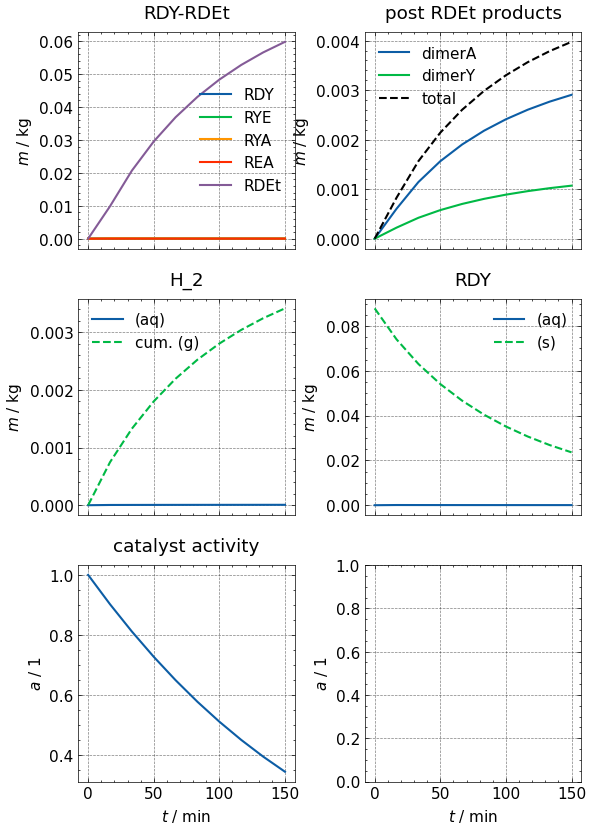

In [8]:
plot_hydrogenation_results(sol)

In [9]:
exp_data = {
    "t_obs": np.asarray(t),
    "y0_obs": np.asarray(y0),
    "y_obs": np.asarray(sol.y).T,
    "params_obs": np.asarray([p, m_s0]),
}

In [10]:
Ts = jnp.linspace(280, 400, 100)  # K

y0s = jnp.zeros((Ts.shape[0], y0.shape[0]))

y0s = y0s.at[:, 0:14].set(m_li0)
y0s = y0s.at[:, 14].set(m_s0)
y0s = y0s.at[:, 16].set(Ts)
y0s = y0s.at[:, 17].set(1.0)

print(y0s.shape)

paramses = jnp.tile(params, (Ts.shape[0], 1))
print(paramses.shape)

(100, 18)
(100, 5)


In [11]:
jsols = jax.block_until_ready(_jitted_vec_forward_solve(y0s, t, paramses))

In [12]:
cust_solve = jax.jit(jax.vmap(_jitted_forward_solve, in_axes=(0, 0, 0)))

In [13]:
# jax.block_until_ready(cust_solve(y0s, jnp.tile(t, (y0s.shape[0], 1)), paramses))

In [14]:
# vecsols = _vec_forward_solve(y0s, t, paramses)

In [15]:
# print(y0.shape)
# sols = []
# for i in range(len(Ts)):
#     sol = _jitted_forward_solve(y0s[i, :], t, paramses[i, :])
#     sols.append(sol)

# sols = jnp.array(sols)

In [16]:
# i = 80
# print(jnp.isclose(jsols, sols).all(axis=[0, 1]))
# # print(jnp.isclose(jsols, vecsols).all())

## check if the model can be run with pymc

In [17]:
from HSA_Cam_B_001 import bmodel
import pytensor as pt
import pymc as pm

In [18]:
model = bmodel(**exp_data)

In [19]:
with model:
    idata = pm.sample_prior_predictive(samples=25, random_seed=43)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\jax\linker.py:32: UserWarning: The RandomType SharedVariables [RNG(<Generator(PCG64) at 0x1B0C0ED90E0>), RNG(<Generator(PCG64) at 0x1B0C0ED9E00>), RNG(<Generator(PCG64) at 0x1B0C10E5D20>), RNG(<Generator(PCG64) at 0x1B0C0ED9D20>), RNG(<Generator(PCG64) at 0x1B0C0EDA0A0>)] will not be used in the compiled JAX graph. Instead a copy will be used.
  warnings.warn(
Sampling: [EA_deact, LH2, k_deact, n_deact, sigma]


C:\Users\hanne\AppData\Local\Temp\ipykernel_33384\3157228217.py:83: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0, 1].legend()
C:\Users\hanne\AppData\Local\Temp\ipykernel_33384\3157228217.py:99: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[1, 0].legend()
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


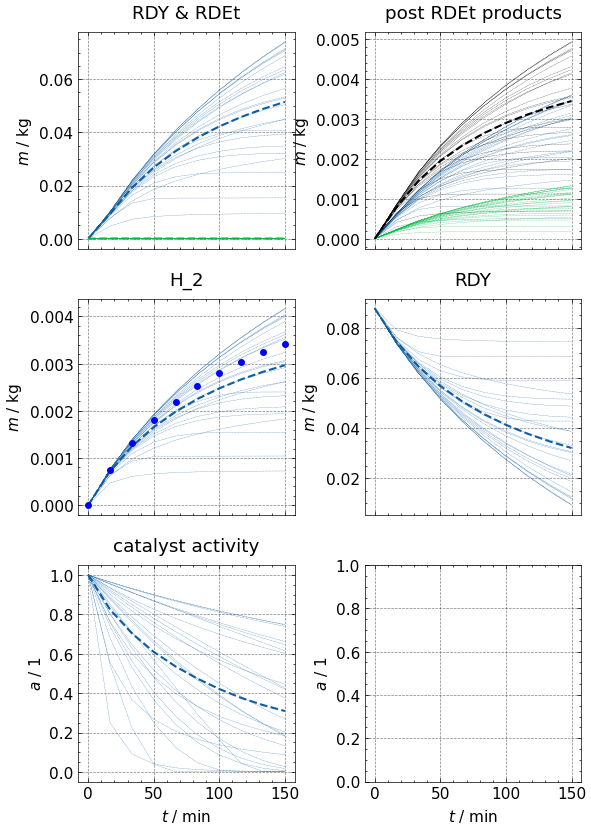

In [20]:
fig, axs = plot_posterior_results(exp_data["t_obs"], idata)
axs[1, 0].plot(exp_data["t_obs"] / 60, exp_data["y_obs"][:, SIDX["conH2[G]"]], "bo")
plt.show()

In [ ]:
import nutpie, numpyro

vars_list = list(model.values_to_rvs.keys())[:-1]
with model:
    posterior_idata = pm.sample(
        # step=[pm.DEMetropolisZ(vars=vars_list)],
        tune=200,
        draws=1000,
        random_seed=43,
        # target_accept=0.95,
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k_deact, EA_deact, n_deact, sigma]


Output()

array([[<Axes: title={'center': 'k_deact'}>,
        <Axes: title={'center': 'k_deact'}>],
       [<Axes: title={'center': 'EA_deact'}>,
        <Axes: title={'center': 'EA_deact'}>],
       [<Axes: title={'center': 'n_deact'}>,
        <Axes: title={'center': 'n_deact'}>]], dtype=object)

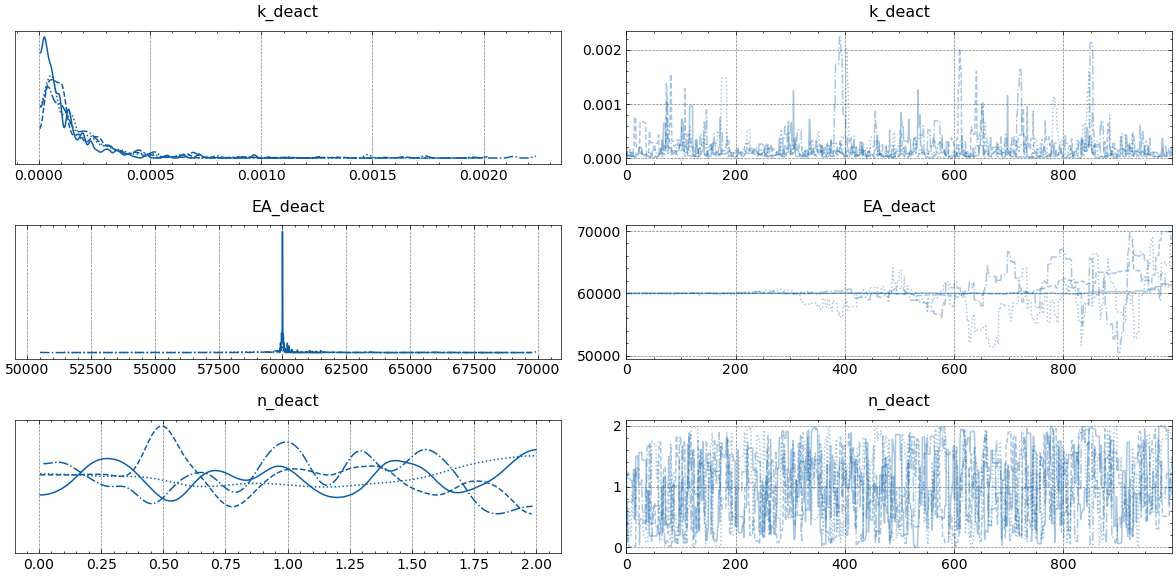

In [ ]:
import arviz as az

az.plot_trace(posterior_idata, var_names=["k_deact", "EA_deact", "n_deact"])

C:\Users\hanne\AppData\Local\Temp\ipykernel_18976\3157228217.py:83: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0, 1].legend()
C:\Users\hanne\AppData\Local\Temp\ipykernel_18976\3157228217.py:99: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[1, 0].legend()


(<Figure size 630x945 with 6 Axes>,
 array([[<Axes: title={'center': 'RDY & RDEt'}, ylabel='$m$ / $\\mathrm{kg}$'>,
         <Axes: title={'center': 'post RDEt products'}, ylabel='$m$ / $\\mathrm{kg}$'>],
        [<Axes: title={'center': 'H_2'}, ylabel='$m$ / $\\mathrm{kg}$'>,
         <Axes: title={'center': 'RDY'}, ylabel='$m$ / $\\mathrm{kg}$'>],
        [<Axes: title={'center': 'catalyst activity'}, xlabel='$t$ / $\\mathrm{min}$', ylabel='$a$ / 1'>,
         <Axes: xlabel='$t$ / $\\mathrm{min}$', ylabel='$a$ / 1'>]],
       dtype=object))

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)


Error in callback <function _draw_all_if_interactive at 0x0000020DCEF1BBA0> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


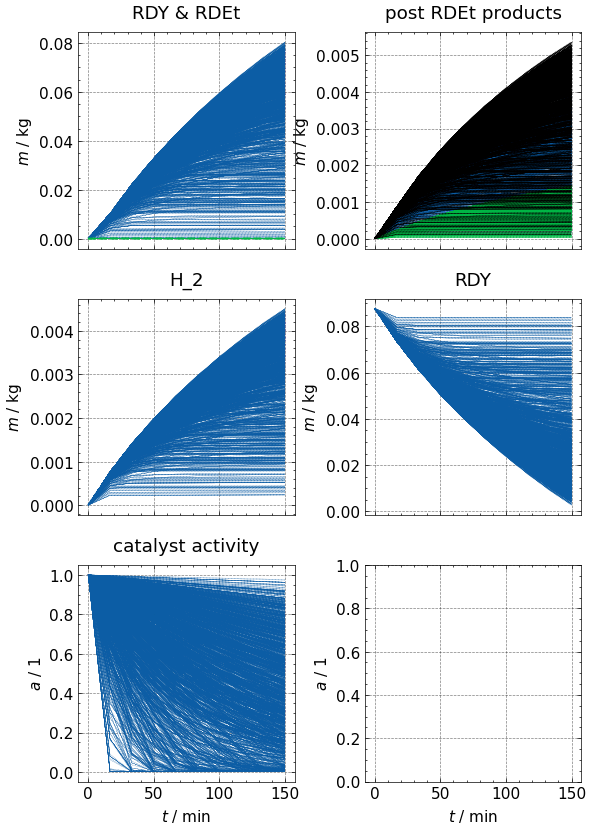

In [ ]:
plot_posterior_results(
    exp_data["t_obs"],
    az.extract(posterior_idata, num_samples=25),
    key="posterior",
)